<a href="https://colab.research.google.com/github/seonilj/ml-neural-networks-for-neuroscience/blob/main/hw2_svm/hw2_main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SVM and Perceptron on Simulated Data

Author: Seonil | Seed: 42 | Helper modules: `hw2/` (HW2-specific) and `common/`

| Section | Content |
|---|---|
| 1 | Dataset simulation (linear and circular) |
| 2 | Perceptron vs. linear SVM |
| 3 | SVM kernels (RBF vs. polynomial) |
| 4 | Data augmentation (+ bonus: 70% threshold) |
| 5 | Label noise |
| 6 | High dimensionality |
| 7 | Summary |

In [45]:
# third-party imports used throughout the notebook

import warnings
import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.exceptions import ConvergenceWarning

## 0. Setup
### 0.1 Mount Drive and set paths

In [ ]:
# Connect to the drive & generate a folder

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/Colab Notebooks/ml-neural-networks-for-neuroscience")
for sub in ["common", "hw2_svm/hw2", "hw2_svm/figs"]:
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

# empty files so Python treats these folders as packages
(ROOT / "common" / "__init__.py").touch()
(ROOT / "hw2_svm" / "hw2" / "__init__.py").touch()

Mounted at /content/drive


In [ ]:
# Set paths & auto reload

import sys

# project folder (ROOT comes from cell 1, so run cell 1 first after any restart)
%cd "/content/drive/MyDrive/Colab Notebooks/ml-neural-networks-for-neuroscience"
sys.path.append(str(ROOT))                 # makes common/ importable
sys.path.append(str(ROOT / "hw2_svm"))     # makes hw2/ importable

/content/drive/MyDrive/Colab Notebooks/ml-neural-networks-for-neuroscience


### 0.2 Create project files (run once)

In [ ]:
# requirements.txt

%%writefile requirements.txt
numpy>=1.24
pandas>=2.0
scikit-learn>=1.3
matplotlib>=3.7
jupyter

Overwriting requirements.txt


In [ ]:
# .gitignore

%%writefile .gitignore
.ipynb_checkpoints/
__pycache__/
*.pyc

Overwriting .gitignore


In [ ]:
# hw2_svm/hw2/data.py (Data generation)

%%writefile hw2_svm/hw2/data.py
"""Dataset generators for HW2."""
import numpy as np
from sklearn.datasets import make_blobs, make_circles
from sklearn.model_selection import train_test_split

SEED = 42


def make_linear_data(n=10_000, n_features=2, spread=3.0, std=0.9, seed=SEED):
    """Two well-separated Gaussian clusters (linearly separable)."""
    centers = np.array([[-spread] * n_features, [spread] * n_features])
    X, y = make_blobs(n_samples=n, centers=centers, cluster_std=std,
                      random_state=seed)
    return X, y


def make_circular_data(n=10_000, factor=0.5, noise=0.08, seed=SEED):
    """Inner circle (class 1) surrounded by an outer ring (class 0)."""
    X, y = make_circles(n_samples=n, factor=factor, noise=noise,
                        random_state=seed)
    return X, y


def split_data(X, y, test_size=0.3, seed=SEED):
    """Train/test split that keeps the class balance."""
    return train_test_split(X, y, test_size=test_size,
                            stratify=y, random_state=seed) # sequence: X_train, X_test, y_train, y_test

Overwriting hw2_svm/hw2/data.py


In [ ]:
# common/plots.py

%%writefile common/plots.py
"""Shared plot helpers."""
import matplotlib.pyplot as plt

COLORS = {0: "tab:blue", 1: "tab:red"}


def plot_scatter(ax, X, y, title=""):
    """Scatter plot of a 2D dataset, colored by class."""
    for label, color in COLORS.items():
        pts = X[y == label]
        ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.5,
                   color=color, label=f"Class {label}")
    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_aspect("equal")
    ax.legend(markerscale=3)


def plot_datasets(datasets, save_path=None):
    """Plot several datasets side by side. datasets = {title: (X, y)}"""
    fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 5))
    for ax, (title, (X, y)) in zip(axes, datasets.items()):
        plot_scatter(ax, X, y, title)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

Overwriting common/plots.py


## 1. Dataset simulation (Q1)

Linear: X=(10000, 2), class counts=[5000 5000]
Circular: X=(10000, 2), class counts=[5000 5000]


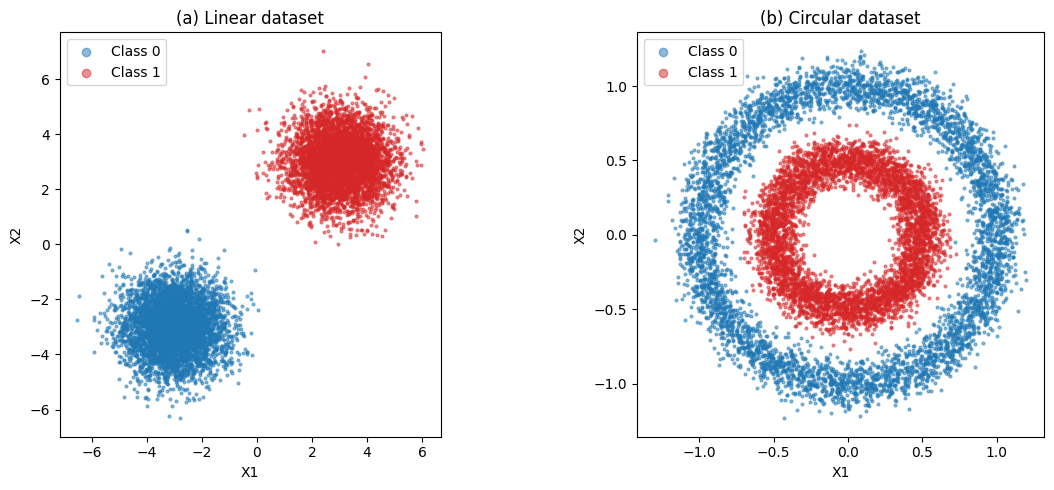

In [ ]:
# Execute Q1 part

import numpy as np
from hw2.data import make_linear_data, make_circular_data, split_data
from common.plots import plot_datasets

X_lin, y_lin = make_linear_data()
X_circ, y_circ = make_circular_data()

# sanity check: shapes and class balance
for name, (X, y) in {"Linear": (X_lin, y_lin), "Circular": (X_circ, y_circ)}.items():
    print(f"{name}: X={X.shape}, class counts={np.bincount(y)}")

plot_datasets(
    {"(a) Linear dataset": (X_lin, y_lin),
     "(b) Circular dataset": (X_circ, y_circ)},
    save_path=str(ROOT / "hw2_svm" / "figs" / "q1_datasets.png"),
)

# split once here and reuse the same split in every later question
Xtr_lin, Xte_lin, ytr_lin, yte_lin = split_data(X_lin, y_lin)
Xtr_circ, Xte_circ, ytr_circ, yte_circ = split_data(X_circ, y_circ)

I simulated n = 10,000 points per dataset with a fixed seed (42).
*   Two Gaussian clusters centered at (-3, -3) and (3, 3), SD = 0.9: the classes do not overlap and a straight line can separate them.
*   An inner circle surrounded by an outer circle (factor = 0.5, noise = 0.08):
no straight line can separate the classes.

## 2. Perceptron vs. linear SVM (Q2)

### 2.1 Helper modules (run once)

In [ ]:
# common/evaluate.py

%%writefile common/evaluate.py
"""Shared evaluation helpers."""
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score


def evaluate(model, X, y):
    """Main metrics of a fitted binary classifier, returned as a dict."""
    pred = model.predict(X)
    return {
        "accuracy": accuracy_score(y, pred),
        "f1": f1_score(y, pred),
        # AUC needs a continuous score, not the 0/1 prediction
        "auc": roc_auc_score(y, model.decision_function(X)),
    }


def compare_models(models, X, y):
    """models = {name: fitted model}  ->  one row of metrics per model."""
    table = {name: evaluate(m, X, y) for name, m in models.items()}
    return pd.DataFrame(table).T.round(3)


def margin_width(model, X):
    """Width of the empty band around a linear boundary (2 x closest distance)."""
    dist = np.abs(model.decision_function(X)) / np.linalg.norm(model.coef_[0])
    return 2 * dist.min()

Overwriting common/evaluate.py


In [ ]:
# hw2/models.py

%%writefile hw2_svm/hw2/models.py
"""Model factories for HW2 (one place to change hyperparameters)."""
from sklearn.linear_model import Perceptron
from sklearn.svm import LinearSVC

from hw2.data import SEED


def make_perceptron(seed=SEED):
    return Perceptron(max_iter=1000, tol=1e-3, random_state=seed)


def make_linear_svm(C=1.0, seed=SEED):
    # hinge loss = the textbook SVM objective
    return LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000,
                     random_state=seed)

Overwriting hw2_svm/hw2/models.py


In [ ]:
# common/plots.py (Expanding)

%%writefile common/plots.py
"""Shared plot helpers."""
import numpy as np
import matplotlib.pyplot as plt

COLORS = {0: "tab:blue", 1: "tab:red"}


def plot_scatter(ax, X, y, title=""):
    """Scatter plot of a 2D dataset, colored by class."""
    for label, color in COLORS.items():
        pts = X[y == label]
        ax.scatter(pts[:, 0], pts[:, 1], s=4, alpha=0.5,
                   color=color, label=f"Class {label}")
    ax.set_title(title)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_aspect("equal")
    ax.legend(markerscale=3)


def plot_datasets(datasets, save_path=None):
    """Plot several datasets side by side. datasets = {title: (X, y)}"""
    fig, axes = plt.subplots(1, len(datasets), figsize=(6 * len(datasets), 5))
    for ax, (title, (X, y)) in zip(axes, datasets.items()):
        plot_scatter(ax, X, y, title)
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_decision_boundary(ax, model, X, y, title="", show_margin=False):
    """Shade the predicted regions, draw the boundary (and margin), then the data."""
    pad = 0.5
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, 300),
        np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, 300),
    )
    scores = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # background: blue where the model predicts class 0, red where class 1
    ax.contourf(xx, yy, scores, levels=[-1e9, 0, 1e9],
                colors=[COLORS[0], COLORS[1]], alpha=0.12)
    ax.contour(xx, yy, scores, levels=[0], colors="k", linewidths=2)
    if show_margin:  # only meaningful for SVM: score = -1 and +1
        ax.contour(xx, yy, scores, levels=[-1, 1], colors="k",
                   linestyles="--", linewidths=1)
    plot_scatter(ax, X, y, title)


def draw_line(ax, model, x_range, **kwargs):
    """Draw a linear model's boundary w1*x1 + w2*x2 + b = 0 as a line."""
    (w1, w2), b = model.coef_[0], model.intercept_[0]
    xs = np.array(x_range)
    ax.plot(xs, -(w1 * xs + b) / w2, **kwargs)

Overwriting common/plots.py


In [ ]:
# Reloading & importing (I will write new function but now plots.py is aldready imported)

import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common.plots
importlib.reload(common.plots) # pick up the new functions

from common.plots import plot_scatter, plot_decision_boundary, draw_line
from common.evaluate import compare_models, margin_width
from hw2.models import make_perceptron, make_linear_svm

FIGS = ROOT / "hw2_svm" / "figs"

### 2.2 Fit both models and compare metrics

In [ ]:
# Training & performance table

data = {
    "Linear":   (Xtr_lin, ytr_lin, Xte_lin, yte_lin),
    "Circular": (Xtr_circ, ytr_circ, Xte_circ, yte_circ),
}

fitted = {} # fitted[dataset][model name] -> trained model
tables = []
for data_name, (Xtr, ytr, Xte, yte) in data.items():
    fitted[data_name] = {
        "Perceptron": make_perceptron().fit(Xtr, ytr), # fit() returns the model
        "Linear SVM": make_linear_svm().fit(Xtr, ytr),
    }
    table = compare_models(fitted[data_name], Xte, yte) # evaluated on the TEST set
    table.insert(0, "dataset", data_name)
    tables.append(table)

results_q2 = pd.concat(tables).rename_axis("model").reset_index()
results_q2

,model,dataset,accuracy,f1,auc
0,Perceptron,Linear,1.000,1.000,1.000
1,Linear SVM,Linear,1.000,1.000,1.000
2,Perceptron,Circular,0.641,0.734,0.514
3,Linear SVM,Circular,0.519,0.566,0.482


### 2.3 Decision boundaries

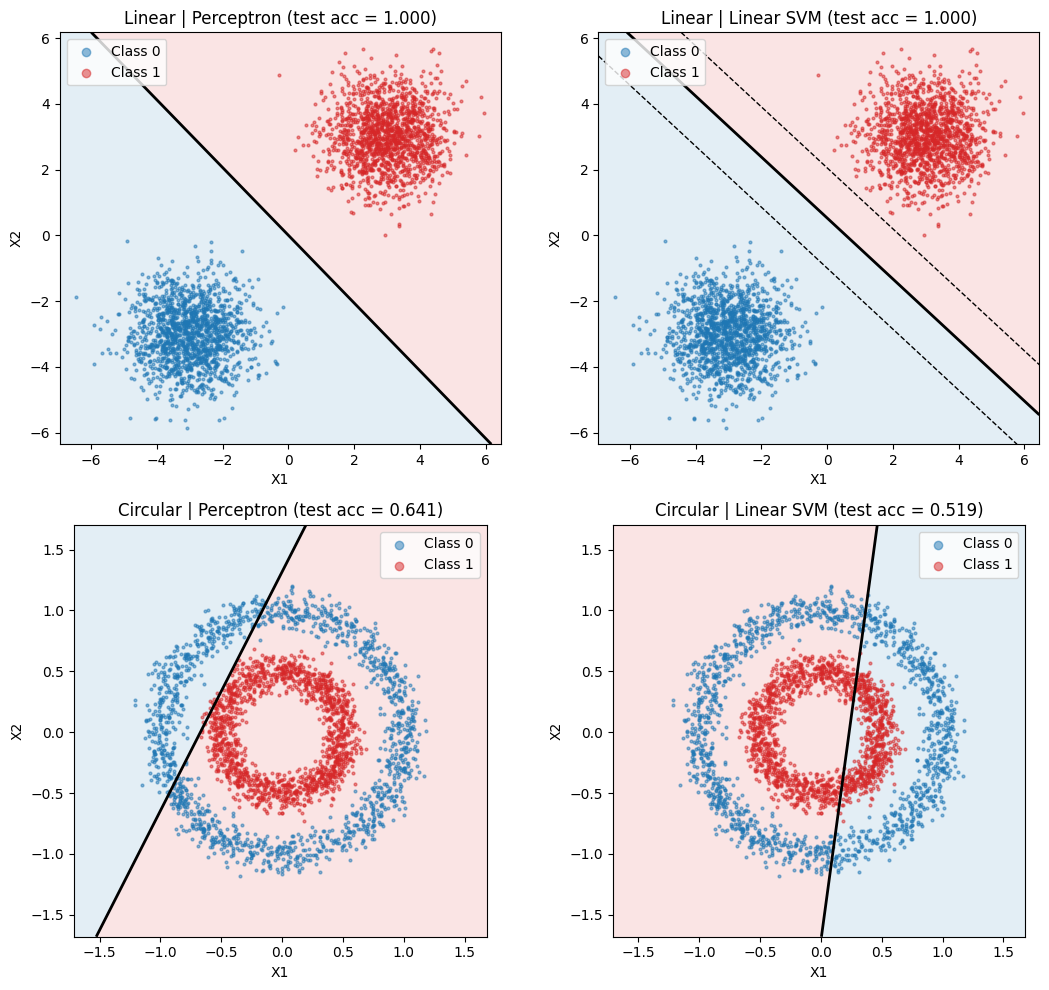

In [ ]:
# Decision boundary 2x2

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for i, (data_name, (Xtr, ytr, Xte, yte)) in enumerate(data.items()):
    for j, (model_name, model) in enumerate(fitted[data_name].items()):
        plot_decision_boundary(
            axes[i, j], model, Xte, yte,
            title=f"{data_name} | {model_name} (test acc = {model.score(Xte, yte):.3f})",
            show_margin=(model_name == "Linear SVM" and data_name == "Linear"),
        )
fig.tight_layout()
fig.savefig(FIGS / "q2_decision_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.4 Perceptron variability and margin (linear data)

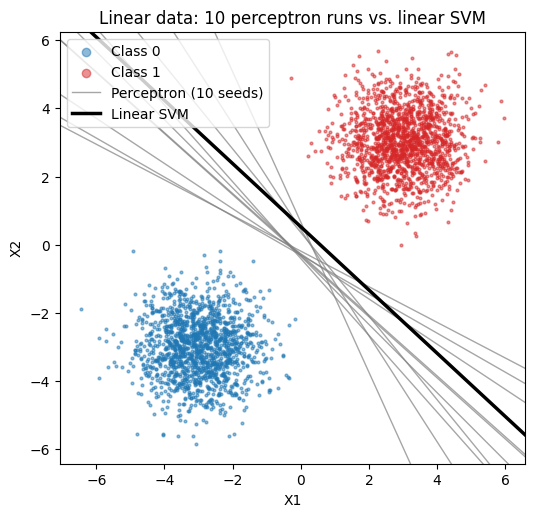

Perceptron margin over 10 seeds: mean=1.19, min=0.81
Linear SVM margin: 2.24


In [ ]:
# Margin comparison: 10 times Perceptron VS. SVM

Xtr, ytr, Xte, yte = data["Linear"]
svm = fitted["Linear"]["Linear SVM"]
perceptrons = [make_perceptron(seed).fit(Xtr, ytr) for seed in range(10)]

fig, ax = plt.subplots(figsize=(6, 6))
plot_scatter(ax, Xte, yte, "Linear data: 10 perceptron runs vs. linear SVM")
xlim, ylim = ax.get_xlim(), ax.get_ylim()       # keep the view fixed
for k, p in enumerate(perceptrons):
    draw_line(ax, p, xlim, color="gray", alpha=0.7, lw=1,
              label="Perceptron (10 seeds)" if k == 0 else None)
draw_line(ax, svm, xlim, color="k", lw=2.5, label="Linear SVM")
ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.legend(markerscale=3)
fig.savefig(FIGS / "q2_perceptron_vs_svm_lines.png", dpi=150, bbox_inches="tight")
plt.show()

margins = [margin_width(p, Xtr) for p in perceptrons]
print(f"Perceptron margin over 10 seeds: mean={np.mean(margins):.2f}, min={np.min(margins):.2f}")
print(f"Linear SVM margin: {margin_width(svm, Xtr):.2f}")

In [ ]:
# how stable is the perceptron on the circular data?
Xtr, ytr, Xte, yte = data["Circular"]
accs = [make_perceptron(seed).fit(Xtr, ytr).score(Xte, yte) for seed in range(10)]
print(f"Perceptron on circular data, 10 seeds: mean={np.mean(accs):.3f}, "
      f"min={np.min(accs):.3f}, max={np.max(accs):.3f}")

Perceptron on circular data, 10 seeds: mean=0.493, min=0.363, max=0.636


### 2.5 Interpretation

| Dataset | Model | Test acc | F1 | AUC |
|---|---|---|---|---|
| Linear | Perceptron | 1.000 | 1.000 | 1.000 |
| Linear | Linear SVM | 1.000 | 1.000 | 1.000 |
| Circular | Perceptron | 0.641 | 0.734 | 0.514 |
| Circular | Linear SVM | 0.519 | 0.566 | 0.482 |

- **Linear data:** both models separate the classes perfectly, so the metrics cannot tell them apart.
  They differ in the boundary: the perceptron stops at the first separating line it finds, so the
  line changes with the sample order (10 seeds, mean margin = 1.19, minimum 0.81), whereas the
  linear SVM picks the maximum-margin line in the middle of the gap (margin = 2.24, about 1.9 times
  the perceptron's mean).
- **Circular data:** no straight line can separate the classes, and both AUCs are at chance level.
  The perceptron's 0.641 was a lucky run: over 10 seeds its accuracy is 0.493 on average
  (range 0.363 to 0.636), i.e. no better than guessing.
- **Conclusion:** a straight line is the wrong hypothesis for ring-shaped data, which motivates a
  non-linear (kernel) SVM in Section 3.

## 3. SVM kernel (Q3)
### 3.1 Helper modules

In [ ]:
# hw2/models.py (Replace all)

%%writefile hw2_svm/hw2/models.py
"""Model factories for HW2 (one place to change hyperparameters)."""
from sklearn.linear_model import Perceptron
from sklearn.svm import LinearSVC, SVC

from hw2.data import SEED


def make_perceptron(seed=SEED):
    return Perceptron(max_iter=1000, tol=1e-3, random_state=seed)


def make_linear_svm(C=1.0, seed=SEED):
    # hinge loss = the textbook SVM objective
    return LinearSVC(C=C, loss="hinge", dual=True, max_iter=20000,
                     random_state=seed)


def make_kernel_svm(kernel="rbf", C=1.0, gamma="scale", degree=2):
    """Kernel SVM. degree is only used by the polynomial kernel."""
    return SVC(kernel=kernel, C=C, gamma=gamma, degree=degree)

Overwriting hw2_svm/hw2/models.py


In [ ]:
# common/eval_plots.py (New file)

%%writefile common/eval_plots.py
"""Evaluation figures: confusion matrix and ROC curve."""
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay


def plot_confusion(ax, model, X, y, title=""):
    """Confusion matrix (counts) of a fitted classifier on (X, y)."""
    ConfusionMatrixDisplay.from_estimator(model, X, y, ax=ax,
                                          cmap="Blues", colorbar=False)
    ax.set_title(title)


def plot_roc(ax, models, X, y):
    """ROC curves of several fitted models on one axis. models = {name: model}"""
    for name, model in models.items():
        RocCurveDisplay.from_estimator(model, X, y, ax=ax, name=name)
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
    ax.set_title("ROC curves")
    ax.legend(loc="lower right")

Overwriting common/eval_plots.py


In [ ]:
# Callback & import

import importlib
import hw2.models
importlib.reload(hw2.models) # pick up make_kernel_svm

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV

from hw2.models import make_kernel_svm
from common.plots import COLORS
from common.eval_plots import plot_confusion, plot_roc
from common.evaluate import evaluate

### 3.2 Why a kernel works: lifting the circular data

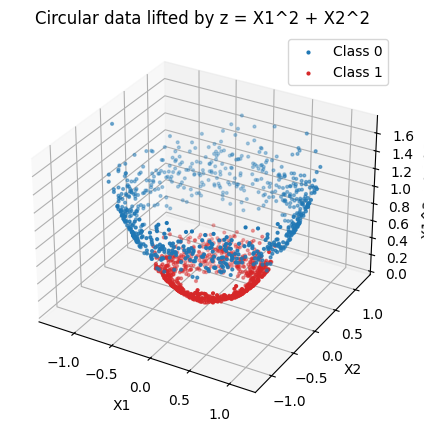

In [ ]:
# Snapshot of lifting

# add a third axis z = X1^2 + X2^2 (squared distance from the center)
fig = plt.figure(figsize=(6, 5))
ax = fig.add_subplot(projection="3d")
Xs, ys = Xtr_circ[:1500], ytr_circ[:1500] # a subset is enough to see the shape
for label, color in COLORS.items():
    pts = Xs[ys == label]
    ax.scatter(pts[:, 0], pts[:, 1], (pts ** 2).sum(axis=1),
               s=4, color=color, label=f"Class {label}")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X1^2 + X2^2")
ax.set_title("Circular data lifted by z = X1^2 + X2^2")
ax.legend()
fig.savefig(FIGS / "q3_lifting_3d.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Tune each kernel (3-fold CV on the training set only)

In [ ]:
# Tuning per kernel

candidates = {
    "RBF":          ("rbf",  {"C": [0.1, 1, 10], "gamma": [0.5, 2, 8]}),
    "Poly (deg 2)": ("poly", {"C": [0.1, 1, 10]}),
}

Xtr, ytr, Xte, yte = data["Circular"]
searches = {}
for name, (kernel, grid) in candidates.items():
    search = GridSearchCV(make_kernel_svm(kernel), grid, cv=3, n_jobs=-1) # 3-fold CV on train set only; test set held out for fair comparison, using all CPU
    searches[name] = search.fit(Xtr, ytr)
    print(f"{name}: best params = {search.best_params_}, "
          f"CV accuracy = {search.best_score_:.4f}")

# best model of each search, already refit on the full training set
kernel_models = {name: s.best_estimator_ for name, s in searches.items()} # best_estimator_: Re-trained with the best combination

RBF: best params = {'C': 10, 'gamma': 8}, CV accuracy = 0.9994
Poly (deg 2): best params = {'C': 1}, CV accuracy = 0.9996


### 3.4 Test-set metrics

In [ ]:
# the linear SVM from Q2 is kept as the baseline
all_models = {"Linear SVM (Q2)": fitted["Circular"]["Linear SVM"], **kernel_models}
results_q3 = compare_models(all_models, Xte, yte)

for name, model in kernel_models.items():
    s = searches[name]
    print(f"{name}: support vectors = {model.n_support_.sum()}, "
          f"fit time = {s.cv_results_['mean_fit_time'][s.best_index_]:.2f}s")

results_q3

RBF: support vectors = 48, fit time = 0.04s
Poly (deg 2): support vectors = 104, fit time = 0.06s


,accuracy,f1,auc
Linear SVM (Q2),0.519,0.566,0.482
RBF,1.000,1.000,1.000
Poly (deg 2),1.000,1.000,1.000


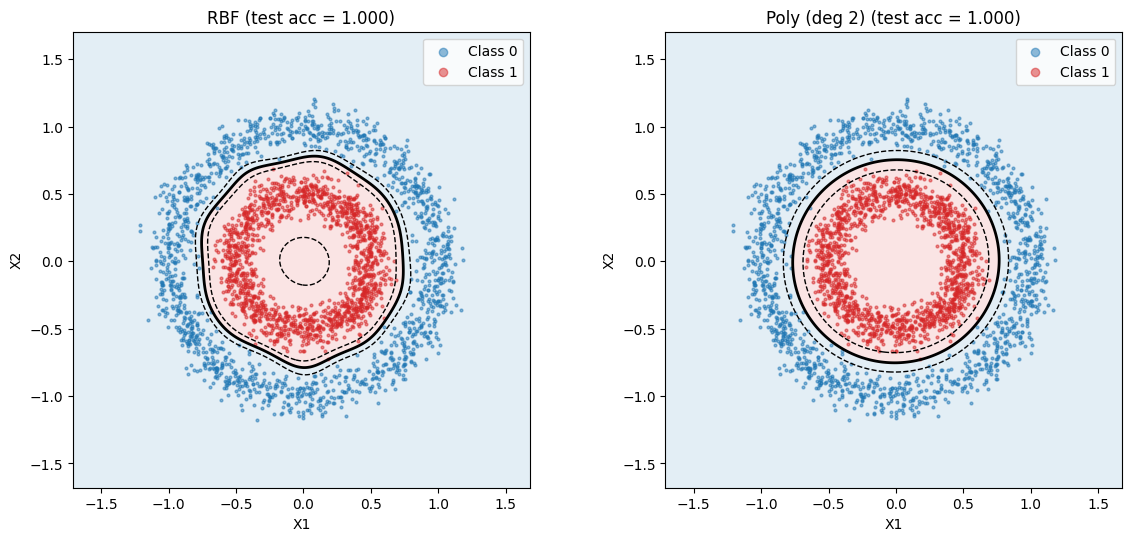

In [ ]:
# Image of decision boundaries

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, (name, model) in zip(axes, kernel_models.items()):
    plot_decision_boundary(ax, model, Xte, yte,
                           title=f"{name} (test acc = {model.score(Xte, yte):.3f})",
                           show_margin=True)
fig.tight_layout()
fig.savefig(FIGS / "q3_kernel_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

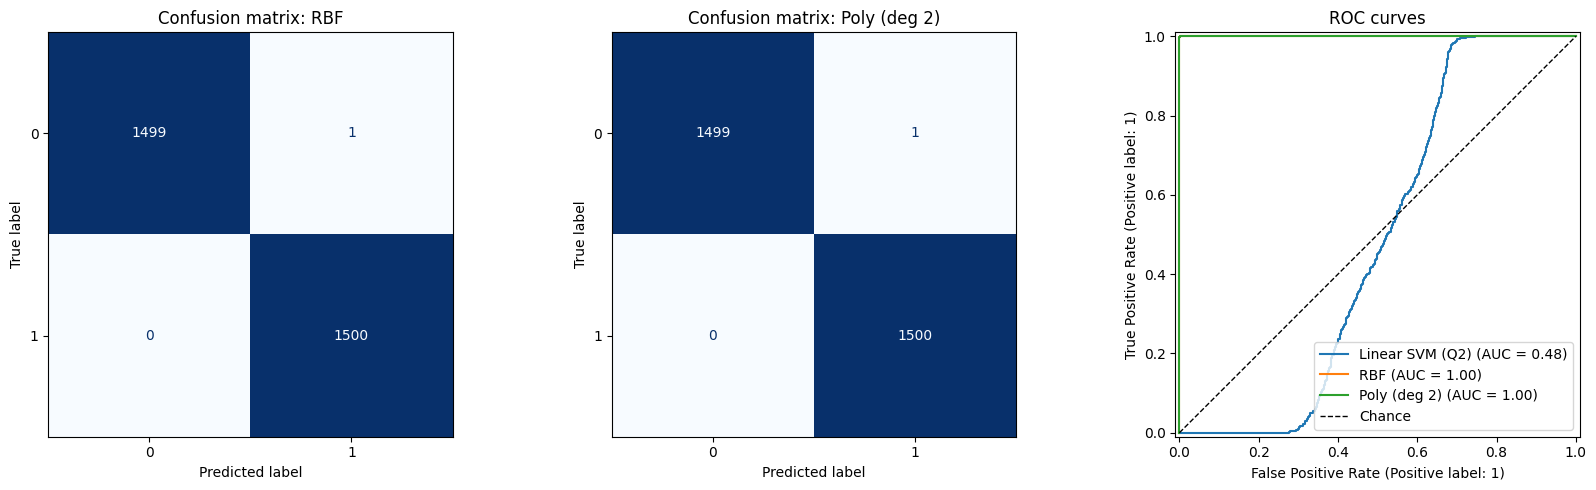

In [ ]:
# confusion matrix + ROC

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (name, model) in zip(axes[:2], kernel_models.items()):
    plot_confusion(ax, model, Xte, yte, title=f"Confusion matrix: {name}")
plot_roc(axes[2], all_models, Xte, yte)
fig.tight_layout()
fig.savefig(FIGS / "q3_confusion_roc.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.5 Which kernel is better? (Repeat on 5 new datasets)

In [ ]:
# Repeat 5 dataset to check the actual differences

rows = []
for seed in range(5):
    X, y = make_circular_data(seed=seed)
    Xtr_s, Xte_s, ytr_s, yte_s = split_data(X, y, seed=seed)
    for name, model in kernel_models.items():
        m = clone(model).fit(Xtr_s, ytr_s)       # same hyperparameters, fresh fit
        rows.append({"model": name, **evaluate(m, Xte_s, yte_s)})

repeat_q3 = (pd.DataFrame(rows)
               .groupby("model")[["accuracy", "f1", "auc"]]
               .agg(["mean", "std"]).round(4))
repeat_q3

accuracy              f1          auc     
                 mean     std    mean     std mean  std
model                                                  
Poly (deg 2)   0.9991  0.0004  0.9991  0.0004  1.0  0.0
RBF            0.9989  0.0004  0.9989  0.0004  1.0  0.0

In [ ]:
BEST_NAME = "RBF" # Based on accuracy and F1 mean values
best_svm = kernel_models[BEST_NAME]
print(BEST_NAME, best_svm.get_params())

RBF {'C': 10, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 2, 'gamma': 8, 'kernel': 'rbf', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}


### 3.7 Interpretation

| Model | Test acc | F1 | AUC | Acc. over 5 new datasets | Support vectors | Hyperparameters |
|---|---|---|---|---|---|---|
| Linear SVM (Q2) | 0.519 | 0.566 | 0.482 | - | - | C = 1 (default) |
| RBF | 1.000 | 1.000 | 1.000 | 0.9989 ± 0.0004 | 48 | C = 10, gamma = 8 |
| Polynomial (degree 2) | 1.000 | 1.000 | 1.000 | 0.9991 ± 0.0004 | 104 | C = 1 |

* Adding a kernel lets the SVM separate the circular dataset: test accuracy rises from 0.519 to 1.000 and AUC from 0.482 to 1.000.
* The polynomial kernel works because the class boundary x1^2 + x2^2 = r^2 is linear in the squared features, and the RBF kernel approximates any smooth
boundary through local similarity.
* Hyperparameters were chosen by 3-fold CV on the training set only.
* Over 5 newly simulated datasets the two kernels are indistinguishable (accuracy 0.9989 vs. 0.9991, difference smaller than one SD of 0.0004); both are close to the ceiling of about 99.9% imposed by the noise of the data itself.
* I select the RBF kernel for the following sections because it reaches the same performance with fewer support vectors (48 vs. 104) and a slightly faster fit.

## 4. Data augmentation (Q4)

**Method:**
* The tuned RBF-SVM is kept fixed.
* Each augmented dataset takes 1,000 random points of the held-out test set and moves every point by Gaussian noise N(0, sigma^2) per coordinate, with
sigma = 0.02 (low) or 0.2 (high), repeated K = 2,000 times in two ways: (i) independent: every round starts from a new random sample; (ii) cumulative: every round continues from the previous one, so the points drift like a random walk.

### 4.1 Helper module

In [ ]:
%%writefile hw2_svm/hw2/augment.py
"""Gaussian-noise augmentation and its evaluation (Q4)."""
import numpy as np
import pandas as pd

from common.evaluate import evaluate
from common.plots import plot_decision_boundary
from hw2.data import SEED


def add_gaussian_noise(X, sigma, rng):
    """Move every point in a random direction: X + N(0, sigma^2) per coordinate."""
    return X + rng.normal(0.0, sigma, size=X.shape)


def augment_rounds(X, y, sigma, k, n_sample=1000, cumulative=False, seed=SEED):
    """Yield k augmented datasets (round, X_aug, y_aug) of n_sample points each.

    cumulative=False: every round starts from a fresh sample of the original data.
    cumulative=True : round t continues from round t-1, so the points keep
                      drifting like a random walk.
    """
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(X), n_sample, replace=False)
    X_cur, y_cur = X[idx], y[idx]
    for t in range(1, k + 1):
        if not cumulative and t > 1:
            idx = rng.choice(len(X), n_sample, replace=False)
            X_cur, y_cur = X[idx], y[idx]
        X_cur = add_gaussian_noise(X_cur, sigma, rng)
        yield t, X_cur, y_cur # To avoid filing up 2000 sets at once, but per a round


def run_augmentation(model, X, y, sigma, k, cumulative=False, n_sample=1000, seed=SEED):
    """Evaluate a fitted model on k augmented datasets (one row of metrics per round)."""
    rows = [{"round": t, **evaluate(model, Xa, ya)}
            for t, Xa, ya in augment_rounds(X, y, sigma, k, n_sample, cumulative, seed)]
    return pd.DataFrame(rows)


def first_round_below(results, threshold=0.70, metric="accuracy"):
    """First round where the metric drops below the threshold (None if it never does)."""
    below = results.loc[results[metric] < threshold, "round"]
    return int(below.iloc[0]) if len(below) else None


def plot_augmented(ax, model, X_aug, y_aug, title=""):
    """Scatter of an augmented dataset; misclassified points get a black cross."""
    plot_decision_boundary(ax, model, X_aug, y_aug, title)
    wrong = model.predict(X_aug) != y_aug # x mark for incorrect dots through boolean masking
    ax.scatter(X_aug[wrong, 0], X_aug[wrong, 1], marker="x", s=25,
               color="k", linewidths=0.8, label="Misclassified")
    ax.legend(markerscale=2, loc="upper right")

Overwriting hw2_svm/hw2/augment.py


In [ ]:
# Import & setting

from hw2.augment import (augment_rounds, run_augmentation,
                         first_round_below, plot_augmented)

# SD of the Gaussian noise; replace with the values from the assignment PDF if given
SIGMAS = {"Low (0.02)": 0.02, "High (0.2)": 0.2}
K = 2000            # number of augmentation rounds
THRESHOLD = 0.70    # for the bonus

Xtr, ytr, Xte, yte = data["Circular"]

### 4.2 One example of each augmentation

RBF: train acc = 1.000, test acc = 1.000


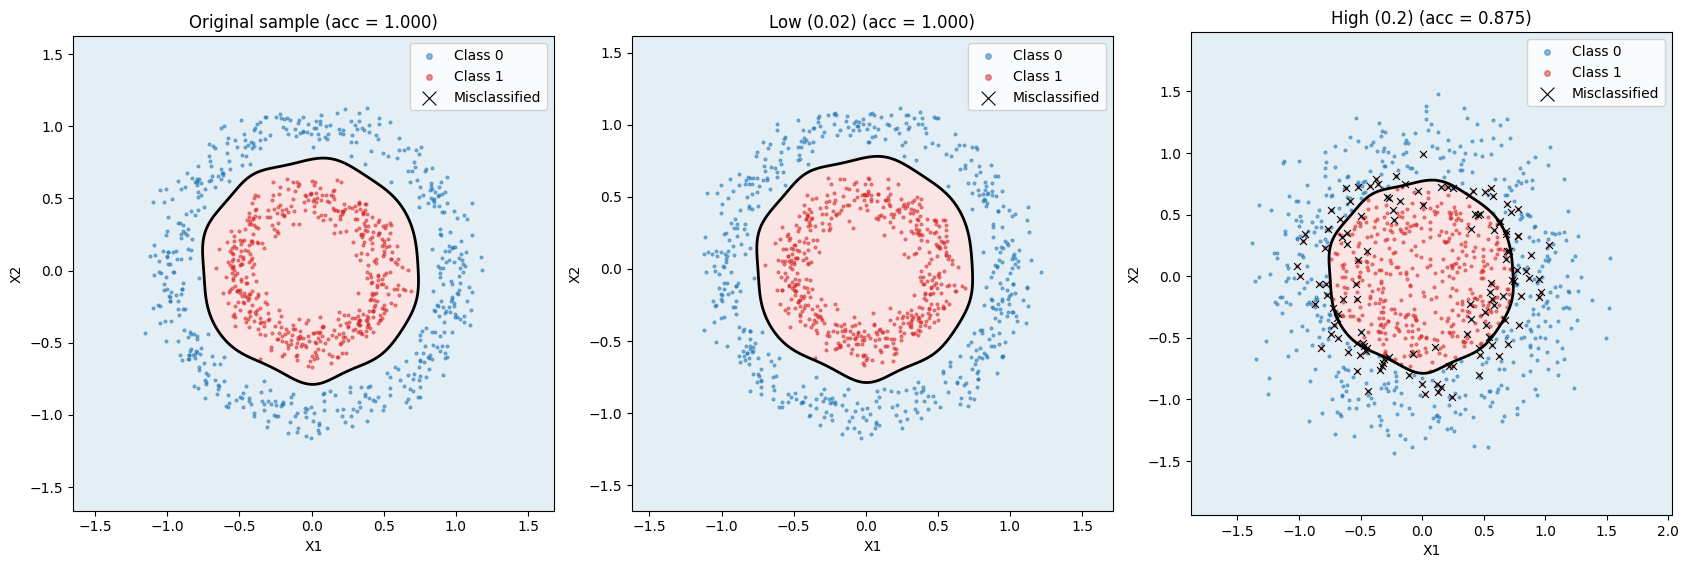

In [ ]:
# Visualisation: Original VS low VS high (x for incorrect dots)

print(f"{BEST_NAME}: train acc = {best_svm.score(Xtr, ytr):.3f}, "
      f"test acc = {best_svm.score(Xte, yte):.3f}")

panels = {"Original sample": 0.0, **SIGMAS}
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (name, sigma) in zip(axes, panels.items()):
    # same seed -> same 1000 points each time, only the noise changes
    _, Xa, ya = next(augment_rounds(Xte, yte, sigma, k=1))
    plot_augmented(ax, best_svm, Xa, ya, f"{name} (acc = {best_svm.score(Xa, ya):.3f})")
fig.tight_layout()
fig.savefig(FIGS / "q4_augmented_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Independent augmentations (K rounds)

accuracy                   f1                  auc              
               mean    std    min   mean    std    min   mean    std    min
noise                                                                      
High (0.2)    0.869  0.010  0.831  0.866  0.011  0.824  0.915  0.009  0.873
Low (0.02)    0.999  0.001  0.995  0.999  0.001  0.995  1.000  0.000  1.000

,accuracy
Train (clean),1.000
Test (clean),1.000
Augmented Low (0.02),0.999
Augmented High (0.2),0.869


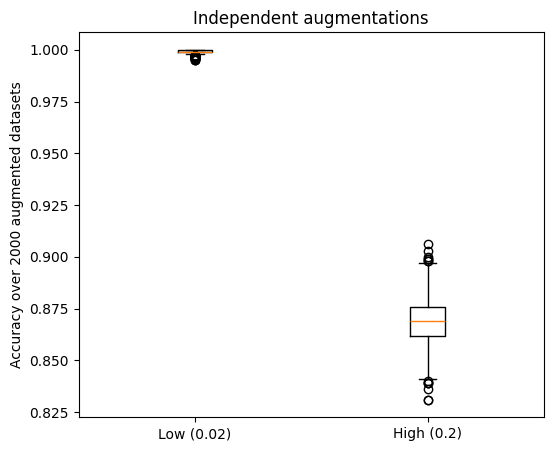

In [ ]:
# Repeatation of independent

indep = {name: run_augmentation(best_svm, Xte, yte, sigma, K)
         for name, sigma in SIGMAS.items()}

summary = (pd.concat(indep, names=["noise"]) # pd.concat(dict, names=["noise"]): Dictionary key(low, high) -> row of a chart
             .groupby("noise")[["accuracy", "f1", "auc"]]
             .agg(["mean", "std", "min"]).round(3))
display(summary)

# generalization overview (clean train/test VS augmented)
gen = pd.Series({
    "Train (clean)": best_svm.score(Xtr, ytr),
    "Test (clean)": best_svm.score(Xte, yte),
    **{f"Augmented {n}": res["accuracy"].mean() for n, res in indep.items()},
}).round(3)
display(gen.to_frame("accuracy"))

fig, ax = plt.subplots(figsize=(6, 5))
ax.boxplot([res["accuracy"] for res in indep.values()])
ax.set_xticklabels(list(indep))
ax.set_ylabel(f"Accuracy over {K} augmented datasets")
ax.set_title("Independent augmentations")
fig.savefig(FIGS / "q4_independent_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Cumulative drift and the threshold %

Low (0.02): accuracy first drops below 70% at round 355
High (0.2): accuracy first drops below 70% at round 5


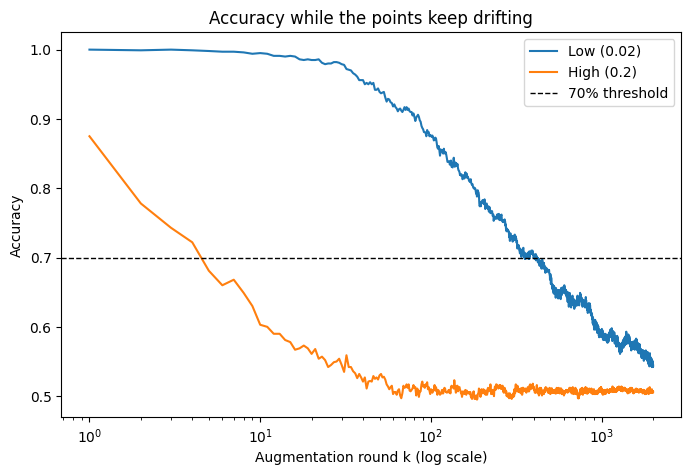

In [ ]:
# Cumulative move & bonus

cumul = {name: run_augmentation(best_svm, Xte, yte, sigma, K, cumulative=True)
         for name, sigma in SIGMAS.items()}

for name, res in cumul.items():
    k_cross = first_round_below(res, THRESHOLD)
    print(f"{name}: accuracy first drops below {THRESHOLD:.0%} at round {k_cross}")

fig, ax = plt.subplots(figsize=(8, 5))
for name, res in cumul.items():
    ax.plot(res["round"], res["accuracy"], label=name)
ax.axhline(THRESHOLD, color="k", ls="--", lw=1, label=f"{THRESHOLD:.0%} threshold")
ax.set_xscale("log")      # the two crossings are orders of magnitude apart
ax.set_xlabel("Augmentation round k (log scale)")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy while the points keep drifting")
ax.legend()
fig.savefig(FIGS / "q4_cumulative_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.5 Interpretation

| Data | Accuracy | F1 | AUC |
|---|---|---|---|
| Train (clean) | 1.000 | - | - |
| Test (clean) | 1.000 | 1.000 | 1.000 |
| Low noise (sigma = 0.02), mean ± SD | 0.999 ± 0.001 | 0.999 ± 0.001 | 1.000 ± 0.000 |
| High noise (sigma = 0.2), mean ± SD | 0.869 ± 0.010 | 0.866 ± 0.011 | 0.915 ± 0.009 |

* **Independent:** low noise barely changes performance, because sigma (0.02) is much smaller than the
  distance from the boundary to each ring (about 0.25). With high noise (sigma = 0.2, close to that
  distance) accuracy drops to 0.869 (worst round 0.831) as points cross the boundary (black crosses
  in the scatter plot). A rough estimate for a perfect circular boundary gives about 0.88, so this
  loss comes from the noise itself rather than from a poorly fitted model.
* **Generalization:** train and clean-test accuracy are equal (1.000 vs. 1.000), so the drop reflects
  sensitivity to noise, not memorization of the training points. AUC (0.915) stays higher than
  accuracy, i.e. most errors occur for points near the boundary.
* **Cumulative (bonus):** the displacement grows like sigma * sqrt(k), so accuracy first falls below
  70% after k = 5 rounds for high noise and k = 355 rounds for low noise (ratio about 71; the
  simple 1/sigma^2 scaling predicts about 100).

## 5. Label noise (Q5)
### 5.1 Helper module

In [ ]:
# Make hw2/noise.py

%%writefile hw2_svm/hw2/noise.py
"""Label-noise helpers (Q5)."""
import numpy as np
import pandas as pd
from sklearn.base import clone

from common.evaluate import evaluate
from hw2.data import SEED


def corrupt_labels(y, fraction, mode="shuffle", seed=SEED):
    """Return a copy of y in which `fraction` of the labels are corrupted.

    mode="shuffle": the chosen labels are permuted among themselves
                    (with balanced classes about half of them stay unchanged).

    mode="flip"   : the chosen labels are inverted (exactly `fraction` are wrong).
    """
    rng = np.random.default_rng(seed)
    y_new = y.copy() # not to touch original labels
    idx = rng.choice(len(y), int(round(fraction * len(y))), replace=False)
    if mode == "shuffle":
        y_new[idx] = rng.permutation(y[idx]) # shuffle for selected labels (change locations)
    elif mode == "flip":
        y_new[idx] = 1 - y[idx] # 0-1 flip
    else:
        raise ValueError(f"unknown mode: {mode}")
    return y_new


def run_label_noise(model, Xtr, ytr, Xte, yte, fractions, mode="shuffle", n_repeats=5):
    """Train on corrupted labels, test on clean labels (one row per fraction and repeat)."""
    rows = []
    for frac in fractions:
        for rep in range(n_repeats):
            y_noisy = corrupt_labels(ytr, frac, mode, seed=SEED + rep)
            m = clone(model).fit(Xtr, y_noisy)
            rows.append({
                "fraction": frac,
                "repeat": rep,
                "wrong_labels": np.mean(y_noisy != ytr), # share that really changed (actual % of incorrect labels)
                "train_acc_noisy": m.score(Xtr, y_noisy), # fit to the noisy labels
                **evaluate(m, Xte, yte), # clean test set
            })
    return pd.DataFrame(rows)

Overwriting hw2_svm/hw2/noise.py


In [ ]:
# Setting

from hw2.noise import run_label_noise

FRACTIONS = [0, 0.05, 0.15, 0.25, 0.35, 0.50]   # 15 / 25 / 50 % are the required ones
N_REPEATS = 5

# name -> (model, train data, test data); linear SVM for linear data, tuned RBF for circular
setups = {
    "Linear data (linear SVM)": (make_linear_svm(), Xtr_lin, ytr_lin, Xte_lin, yte_lin),
    "Circular data (RBF SVM)":  (best_svm, Xtr_circ, ytr_circ, Xte_circ, yte_circ)
}

### 5.2 Train on corrupted labels, test on clean labels

In [ ]:
# Execute experiments

import warnings
from sklearn.exceptions import ConvergenceWarning

# expected: noisy labels cannot be separated, so the linear solver warns
warnings.simplefilter("ignore", ConvergenceWarning)

results = []
for name, (model, Xt, yt, Xv, yv) in setups.items():
    for mode in ["shuffle", "flip"]:
        res = run_label_noise(model, Xt, yt, Xv, yv, FRACTIONS, mode, N_REPEATS) # change N_REPEATS=n if slow
        results.append(res.assign(setup=name, mode=mode))

noise_df = pd.concat(results, ignore_index=True)

In [ ]:
# Make the chart

# test accuracy: one column per (dataset, mode)
acc_table = noise_df.pivot_table(index="fraction", columns=["setup", "mode"],
                                 values="accuracy").round(3)
display(acc_table)

# how many labels are really wrong after "shuffle"? (about half of the fraction)
wrong = noise_df[noise_df["mode"] == "shuffle"].groupby("fraction")["wrong_labels"].mean()
display(wrong.round(3).to_frame("share of wrong labels (shuffle)"))

# memorization check: accuracy on the noisy training labels vs. clean test accuracy
display(noise_df[noise_df["mode"] == "shuffle"]
        .groupby(["setup", "fraction"])[["train_acc_noisy", "accuracy"]].mean().round(3))

setup    Circular data (RBF SVM)         Linear data (linear SVM)        
mode                        flip shuffle                     flip shuffle
fraction                                                                 
0.00                       1.000   1.000                    1.000     1.0
0.05                       1.000   1.000                    1.000     1.0
0.15                       1.000   0.999                    1.000     1.0
0.25                       1.000   1.000                    1.000     1.0
0.35                       1.000   1.000                    1.000     1.0
0.50                       0.493   1.000                    0.513     1.0

,share of wrong labels (shuffle)
fraction,
0.00,0.000
0.05,0.025
0.15,0.074
0.25,0.126
0.35,0.178
0.50,0.247


train_acc_noisy  accuracy
setup                    fraction                           
Circular data (RBF SVM)  0.00                1.000     1.000
                         0.05                0.974     1.000
                         0.15                0.925     0.999
                         0.25                0.874     1.000
                         0.35                0.821     1.000
                         0.50                0.753     1.000
Linear data (linear SVM) 0.00                1.000     1.000
                         0.05                0.975     1.000
                         0.15                0.926     1.000
                         0.25                0.874     1.000
                         0.35                0.822     1.000
                         0.50                0.753     1.000

### 5.3 Performance vs. label noise

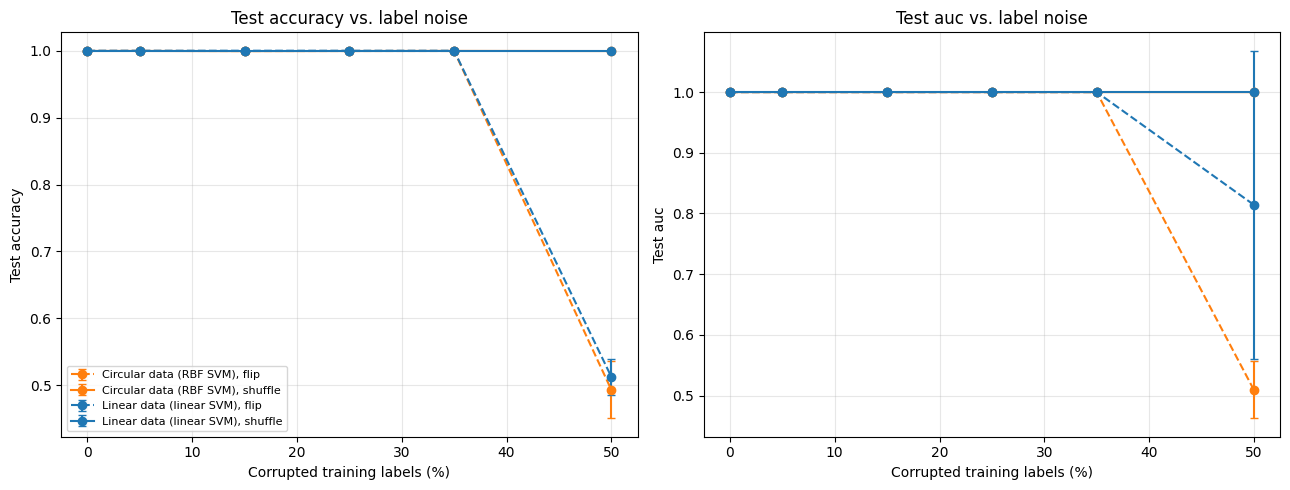

In [ ]:
# Make the graph

colors = {name: f"C{i}" for i, name in enumerate(setups)}

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric in zip(axes, ["accuracy", "auc"]):
    for (setup, mode), g in noise_df.groupby(["setup", "mode"]):
        stats = g.groupby("fraction")[metric].agg(["mean", "std"])
        ax.errorbar(stats.index * 100, stats["mean"], yerr=stats["std"],
                    color=colors[setup], marker="o", capsize=3,
                    ls="-" if mode == "shuffle" else "--",
                    label=f"{setup}, {mode}")
    ax.set_xlabel("Corrupted training labels (%)")
    ax.set_ylabel(f"Test {metric}")
    ax.set_title(f"Test {metric} vs. label noise")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "q5_label_noise.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
noise_df[noise_df["fraction"] == 0.5].groupby(["setup", "mode"])["auc"].agg(["mean", "std"]).round(3)

mean    std
setup                    mode                 
Circular data (RBF SVM)  flip     0.510  0.047
                         shuffle  1.000  0.000
Linear data (linear SVM) flip     0.814  0.254
                         shuffle  1.000  0.000

## 5. Label noise (Q5)

**Method:** A fraction of the labels in the original training sets was corrupted (0, 5, 15, 25, 35 and 50%) and the models were retrained; the test labels stayed clean.
* Two corruptions were used:
"shuffle" (the chosen labels are permuted among themselves, so only about half of them actually change) and "flip" (all chosen labels are inverted).
* I used the linear SVM on the linear dataset and the tuned RBF-SVM on the circular dataset; each point is the mean ± SD of 5 repetitions.

| Corrupted labels | Wrong labels (shuffle) | Linear data, acc (shuffle / flip) | Circular data, acc (shuffle / flip) |
|---|---|---|---|
| 0% | 0% | 1.000 / 1.000 | 1.000 / 1.000 |
| 15% | 7.4% | 1.000 / 1.000 | 0.999 / 1.000 |
| 25% | 12.6% | 1.000 / 1.000 | 1.000 / 1.000 |
| 50% | 24.7% | 1.000 / 0.513 | 1.000 / 0.493 |

- **Shuffle:** even when 50% of the training labels are shuffled (24.7% truly wrong), both models keep a test accuracy of 1.000.
- **Flip:** performance stays at 1.000 up to 35% flipped labels and collapses to chance level only at 50% (0.513 and 0.493), where the labels no longer carry any information.
- **Reason for the robust trait:** the noise is symmetric and independent of position, and with 7,000 dense training points the correct labels remain the majority around every location as long as fewer than
  50% are wrong, so the boundary does not move.
- **No memorization:** the accuracy on the noisy training labels equals the share of correct labels (e.g. 0.753 when 24.7% are wrong, for both models), i.e. the models predict the true class and treat
  the corrupted labels as errors. This holds even for the flexible RBF-SVM (C = 10, gamma = 8).
- At 50% flip the AUC of the circular model is ~0.5, and that of the linear model is unstable (the direction of the line is arbitrary), which confirms that no information is left.
- **Final conclusion:** with a large, dense training set the SVM is highly robust to symmetric label noise and breaks down abruptly only when the labels become random. Robustness is expected to be lower when   the training points are sparse (fewer samples or higher dimensions, see Q6).

In [ ]:
# additional: with only 300 training points, the noise is harder to average out

small = {
    "Linear data (linear SVM), n=300": (make_linear_svm(), Xtr_lin[:300], ytr_lin[:300], Xte_lin, yte_lin),
    "Circular data (RBF SVM), n=300":  (best_svm, Xtr_circ[:300], ytr_circ[:300], Xte_circ, yte_circ),
}

small_df = pd.concat(
    [run_label_noise(m, Xt, yt, Xv, yv, FRACTIONS, "flip", N_REPEATS).assign(setup=name)
     for name, (m, Xt, yt, Xv, yv) in small.items()],
    ignore_index=True,
)
small_df.pivot_table(index="fraction", columns="setup", values="accuracy").round(3)

setup,"Circular data (RBF SVM), n=300","Linear data (linear SVM), n=300"
fraction,,
0.00,0.997,1.000
0.05,0.995,1.000
0.15,0.978,1.000
0.25,0.954,1.000
0.35,0.798,1.000
0.50,0.481,0.533


## 6. High dimensionality (Q6)
### 6.1 Helper module

In [ ]:
# Write hw2/highdim.py

%%writefile hw2_svm/hw2/highdim.py
"""High-dimensional versions of the HW2 datasets (Q6)."""
import numpy as np

from hw2.data import SEED, make_linear_data


def make_linear_highdim(d, n=10_000, seed=SEED):
    """Two Gaussian clusters in d dimensions. The distance between the centers is
    kept at its 2D value (about 8.5), so only the dimension changes."""
    spread = 3.0 * np.sqrt(2 / d) # centers at +-spread on every axis
    return make_linear_data(n=n, n_features=d, spread=spread, seed=seed)


def make_circular_highdim(d, n=10_000, radii=(1.0, 0.5), noise=0.08, seed=SEED):
    """Two concentric hyperspheres in d dimensions (class 0 outside, class 1 inside)."""
    rng = np.random.default_rng(seed)
    y = rng.permutation(np.repeat([0, 1], n // 2))
    # a normalized Gaussian vector is a uniformly random direction
    directions = rng.normal(size=(n, d))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    radius = np.where(y == 0, radii[0], radii[1]) + rng.normal(0, noise, n)
    return directions * radius[:, None], y

Overwriting hw2_svm/hw2/highdim.py


In [41]:
# Label noise experiment by dimensions

from hw2.highdim import make_linear_highdim, make_circular_highdim

DIMS = [2, 5, 10, 15]
FRACTIONS_6 = [0, 0.15, 0.25, 0.35, 0.50] # share of flipped training labels
N_REPEATS_6 = 3

# dataset maker and model for each setup (gamma="scale" instead of the 2D-tuned 8)
makers = {
    "Linear data (linear SVM)": make_linear_highdim,
    "Circular data (RBF SVM)":  make_circular_highdim,
}
models6 = {
    "Linear data (linear SVM)": make_linear_svm(),
    "Circular data (RBF SVM)":  clone(best_svm).set_params(gamma="scale"),
}

results6 = []
for name, make_data in makers.items():
    for d in DIMS:
        X, y = make_data(d)
        Xt, Xv, yt, yv = split_data(X, y)
        res = run_label_noise(models6[name], Xt, yt, Xv, yv,
                              FRACTIONS_6, "flip", N_REPEATS_6)
        results6.append(res.assign(setup=name, dim=d))

dim_df = pd.concat(results6, ignore_index=True)

In [43]:
# Make the chart

# test accuracy: rows = (dataset, dimension), columns = share of flipped labels
display(dim_df.pivot_table(index=["setup", "dim"], columns="fraction",
                           values="accuracy").round(3))

# memorization check at 25% flipped labels
display(dim_df[dim_df["fraction"] == 0.25]
        .groupby(["setup", "dim"])[["train_acc_noisy", "accuracy"]].mean().round(3))

fraction                       0.00   0.15   0.25   0.35   0.50
setup                    dim                                   
Circular data (RBF SVM)  2    0.999  0.999  0.999  0.999  0.609
                         5    0.998  0.999  0.997  0.960  0.492
                         10   0.998  0.948  0.903  0.848  0.506
                         15   0.999  0.944  0.892  0.827  0.470
Linear data (linear SVM) 2    1.000  1.000  1.000  1.000  0.521
                         5    1.000  1.000  1.000  1.000  0.481
                         10   1.000  1.000  1.000  1.000  0.517
                         15   1.000  1.000  1.000  1.000  0.489

train_acc_noisy  accuracy
setup                    dim                           
Circular data (RBF SVM)  2              0.749     0.999
                         5              0.750     0.997
                         10             0.838     0.903
                         15             0.879     0.892
Linear data (linear SVM) 2              0.750     1.000
                         5              0.750     1.000
                         10             0.750     1.000
                         15             0.750     1.000

### 6.3 Performance vs. dimension

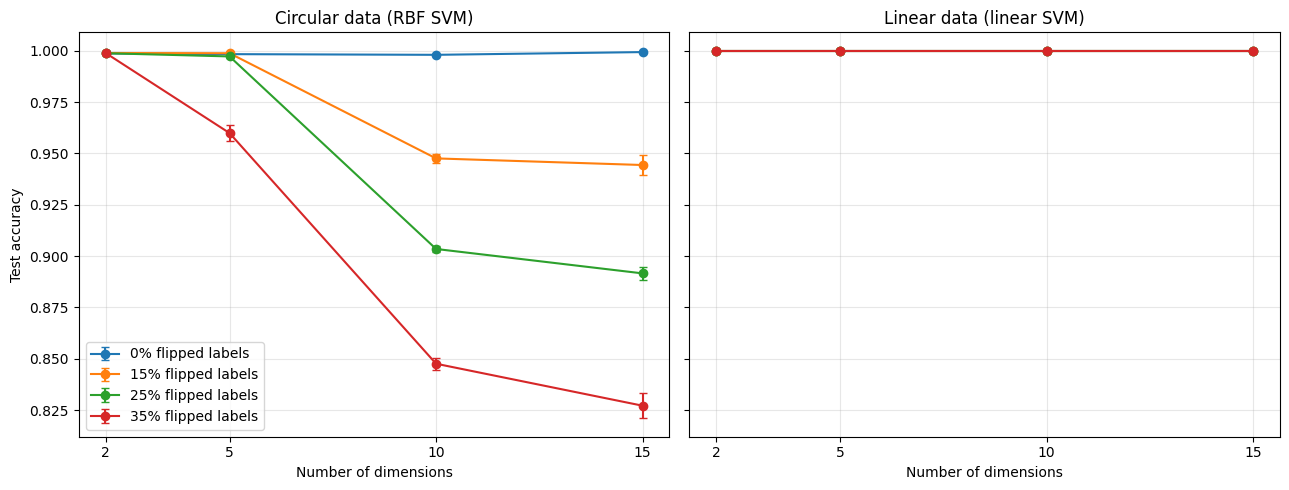

In [42]:
# Make the graph

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, (setup, g) in zip(axes, dim_df.groupby("setup")):
    for frac in [0, 0.15, 0.25, 0.35]:       # 50% is chance level in every dimension
        stats = g[g["fraction"] == frac].groupby("dim")["accuracy"].agg(["mean", "std"])
        ax.errorbar(stats.index, stats["mean"], yerr=stats["std"],
                    marker="o", capsize=3, label=f"{frac:.0%} flipped labels")
    ax.set_xticks(DIMS)
    ax.set_xlabel("Number of dimensions")
    ax.set_title(setup)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Test accuracy")
axes[0].legend()

fig.tight_layout()
fig.savefig(FIGS / "q6_performance_vs_dimension.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Why gamma matters in high dimensions

In [44]:
# Reason why γ is important

def tune_gamma(X, y, gammas=(0.1, 0.5, 2, 8)):
    """Choose gamma for the RBF-SVM by 3-fold CV (C stays at the value from Q3)."""
    search = GridSearchCV(clone(best_svm), {"gamma": list(gammas)}, cv=3, n_jobs=-1)
    return search.fit(X, y).best_estimator_


rows = []
for d in DIMS:
    X, y = make_circular_highdim(d)
    Xt, Xv, yt, yv = split_data(X, y)
    fitted6 = {
        "RBF, gamma = 8 (fixed)":  clone(best_svm).fit(Xt, yt),
        "RBF, gamma = scale":      clone(best_svm).set_params(gamma="scale").fit(Xt, yt),
        "RBF, gamma tuned by CV":  tune_gamma(Xt, yt),
        "Polynomial (degree 2)":   clone(kernel_models["Poly (deg 2)"]).fit(Xt, yt),
    }
    for name, m in fitted6.items():
        rows.append({"dim": d, "model": name, "accuracy": m.score(Xv, yv),
                     "support_vectors": m.n_support_.sum(), "gamma": m.get_params()["gamma"]})

gamma_df = pd.DataFrame(rows)
display(gamma_df.pivot(index="dim", columns="model", values="accuracy").round(3))
display(gamma_df.pivot(index="dim", columns="model", values="support_vectors"))
display(gamma_df[gamma_df["model"] == "RBF, gamma tuned by CV"][["dim", "gamma"]])

model,Polynomial (degree 2),"RBF, gamma = 8 (fixed)","RBF, gamma = scale","RBF, gamma tuned by CV"
dim,,,,
2,0.999,0.999,0.999,0.999
5,0.999,0.997,0.998,0.999
10,0.998,0.996,0.998,0.998
15,1.000,0.994,0.999,1.000


model,Polynomial (degree 2),"RBF, gamma = 8 (fixed)","RBF, gamma = scale","RBF, gamma tuned by CV"
dim,,,,
2,113,63,68,67
5,179,500,95,380
10,261,2479,163,406
15,333,4085,215,423


,dim,gamma
2,2,2
6,5,0.1
10,10,0.1
14,15,0.1


## 6. High dimensionality (Q6)

**Method.** The Q5 label-noise experiment was repeated for d = 2, 5, 10 and 15 dimensions (n = 10,000).
Linear data: two Gaussian clusters whose centers keep the same distance as in 2D. Circular data: two
concentric hyperspheres (radii 1.0 and 0.5, radial noise 0.08). Both problems are therefore equally
easy in principle in every dimension (a quadratic boundary separates the spheres in any d), and only the
sparsity of the data changes. A share of the training labels was flipped; values are means of 3
repetitions (standard deviations are small, see the figure). The linear SVM was used for the linear data
and the RBF-SVM (C = 10, gamma = "scale") for the circular data.

**Test accuracy vs. dimension and share of flipped labels**

| Dimension | Linear data (0% / 25% / 35%) | Circular data (0% / 25% / 35%) |
|---|---|---|
| 2 | 1.000 / 1.000 / 1.000 | 0.999 / 0.999 / 0.999 |
| 5 | 1.000 / 1.000 / 1.000 | 0.998 / 0.997 / 0.960 |
| 10 | 1.000 / 1.000 / 1.000 | 0.998 / 0.903 / 0.848 |
| 15 | 1.000 / 1.000 / 1.000 | 0.999 / 0.892 / 0.827 |

**Kernel and gamma on the circular data (clean labels): accuracy (support vectors)**

| Dimension | Polynomial (deg 2) | RBF, gamma = 8 (fixed) | RBF, gamma = scale | RBF, gamma tuned by CV |
|---|---|---|---|---|
| 2 | 0.999 (113) | 0.999 (63) | 0.999 (68) | 0.999 (67), gamma = 2 |
| 5 | 0.999 (179) | 0.997 (500) | 0.998 (95) | 0.999 (380), gamma = 0.1 |
| 10 | 0.998 (261) | 0.996 (2,479) | 0.998 (163) | 0.998 (406), gamma = 0.1 |
| 15 | 1.000 (333) | 0.994 (4,085) | 0.999 (215) | 1.000 (423), gamma = 0.1 |

- **Linear data** is unaffected by the dimension and by up to 35% flipped labels (accuracy 1.000): a hyperplane cannot memorize wrong labels. At 50% the labels are random and every model is at chance level (0.47-0.61).
- **Clean circular data** is also unaffected (accuracy ≥ 0.994 for every model and dimension).
- **Label noise makes the dimension matter for the RBF-SVM.** At 25% flipped labels the test accuracy falls from 0.999 (d = 2) to 0.892 (d = 15), while the training accuracy on the noisy labels rises from 0.749 to 0.879, i.e. the model starts to memorize wrong labels. In higher dimensions the same 7,000 points are sparse, so each wrong label gets a neighborhood of its own (in 2D the correct labels outvoted it).
- **Gamma and kernel:** gamma = 8 (tuned in 2D) keeps the clean accuracy but needs 4,085 of 7,000 points as support vectors at d = 15 (vs. 215 with gamma = scale); the CV-tuned gamma shrinks from 2 to 0.1 (grid edge). The degree-2 polynomial kernel stays at 0.998-1.000 with 113-333 support vectors, because the boundary sum(x_i^2) = r^2 is quadratic in any dimension.
- **Conclusion:** the robustness found in Q5 depends on dense data. In higher dimensions flexible local models (RBF) are more exposed to label noise, while models that match the form of the problem (linear, quadratic) are not.

## 7. Summary

| Section | Main finding |
|---|---|
| Q1 | Linear and circular datasets (n = 10,000 each, seed 42), stratified 70/30 split |
| Q2 | Both models reach 1.000 on the linear data, but the SVM margin is ~1.9x larger (2.24 vs. 1.19) and independent of the sample order; both fail on the circular data (AUC ~0.5) |
| Q3 | RBF and polynomial (degree 2) kernels both reach ~0.999 and are indistinguishable; RBF chosen (48 vs. 104 support vectors) |
| Q4 | Low noise (0.02): accuracy 0.999; high noise (0.2): 0.869; with cumulative drift, accuracy falls below 70% after 5 (high) and 355 (low) rounds |
| Q5 | No loss up to 35% flipped (or 50% shuffled) labels; 50% flipped = chance; no memorization in 2D |
| Q6 | Linear model unaffected by dimension; RBF becomes label-noise sensitive for d ≥ 10 (25% flips: 0.999 → 0.892 at d = 15); polynomial kernel stays at ~1.0 |